---
title: "Лабораторна робота 8. Відтворюване модельно-обчислювальне дослідження складної системи"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Це фінальна лабораторна робота курсу.

Вона не вводить новий algorithm. Її мета -- інтегрувати результати попередніх робіт у *відтворюваний дослідницький артефакт (Reproducible Research Artifact)*:

$$
RQ
\rightarrow
M
\rightarrow
D
\rightarrow
\Theta
\rightarrow
V\&V
\rightarrow
SA/UQ
\rightarrow
E
\rightarrow
C
\rightarrow
\mathcal R.
$$

Артефактна вертикаль:

$$
v0.1
\rightarrow
v0.2
\rightarrow
\cdots
\rightarrow
v0.7
\rightarrow
\boxed{\text{v1.0 Reproducible Research Artifact}}.
$$

Ключове питання:

$$
\boxed{
\text{Чи можна відтворити шлях від Research Question до scientific claim?}
}
$$

Reproducibility розглядаємо як властивість усього computational research workflow, а не лише доступність code [@antunesHill2024].
:::

# Мета роботи

Сформувати завершений, відтворюваний і простежуваний model-based research workflow, у якому model, data, parameters, configuration, computational environment, experiment, results та scientific claims пов'язані явним provenance chain.

# Завдання роботи

1. Зафіксувати Research Question, intended use та scope.
2. Ідентифікувати model, data і experiment versions.
3. Представити configuration як окремий research artifact.
4. Зафіксувати computational environment.
5. Побудувати executable pipeline без hidden state.
6. Автоматично сформувати result table.
7. Побудувати evidence table.
8. Сформувати bounded scientific claim.
9. Побудувати Claim--Evidence Traceability Matrix.
10. Провести reproducibility audit.
11. Провести claim audit.
12. Інтегрувати artifacts ЛР1--ЛР7 у `Reproducible Research Artifact v1.0`.
13. Перенести структуру artifact на дисертаційне дослідження.

# 1. Що є результатом ЛР8

Результат -- не notebook сам по собі.

Research artifact:

$$
\mathcal R
=
\{
RQ,M,D,\Theta,V\&V,SA,UQ,E,C,P
\},
$$

де:

- $RQ$ -- Research Question;
- $M$ -- model;
- $D$ -- data;
- $\Theta$ -- parameters;
- $V\&V$ -- credibility evidence;
- $SA$ -- sensitivity evidence;
- $UQ$ -- uncertainty evidence;
- $E$ -- experiment;
- $C$ -- claims;
- $P$ -- provenance.

# 2. Мінімальна вимога до відтворюваності

Зошит повинен виконуватися:

> **Restart Kernel → Run All**

без:

- ручного створення проміжних variables;
- прихованого state;
- ручного копіювання результатів;
- залежності від невказаних локальних файлів;
- зміни cell order.

# Частина I. Навчальний інтегрований кейс

# 3. Research Question

Продовжуємо логіку ЛР5--ЛР7.

> Чи зменшує residual hybrid model prediction error відносно calibrated mechanistic baseline у заданому extrapolation regime для synthetic logistic system із time-varying growth rate?

Важливо: це *model-based computational RQ*, а не твердження про будь-яку реальну population.

# 4. Intended use

Модель використовується для:

> порівняння mechanistic і hybrid formulations у контрольованому synthetic experiment.

Не використовується для:

- real-world forecasting;
- causal claims про реальні системи;
- extrapolation поза визначеним horizon;
- оцінювання універсальної переваги hybrid modelling.

# 5. Artifact manifest

Кожен component отримує ID/version.

| Artifact | ID | Version |
|---|---|---|
| Research Question | RQ01 | 1.0 |
| Model specification | M01 | 1.0 |
| Synthetic data | D01 | 1.0 |
| Parameter set | THETA01 | 1.0 |
| Experiment configuration | E01 | 1.0 |
| Analysis pipeline | A01 | 1.0 |
| Result table | R01 | generated |
| Scientific claim | C01 | 1.0 |

# 6. Configuration as data

Усі control values збираємо в одному object.

In [1]:
CONFIG = {
    "artifact_version": "1.0",
    "rq_id": "RQ01",
    "model_id": "M01",
    "data_id": "D01",
    "parameter_id": "THETA01",
    "experiment_id": "E01",
    "analysis_id": "A01",
    "base_seed": 42,
    "observation_seed": 101,
    "x0": 5.0,
    "r0_true": 0.72,
    "K_true": 100.0,
    "modulation_amplitude": 0.18,
    "omega_true": 1.15,
    "sigma_obs": 1.2,
    "time_start": 0.0,
    "time_end": 10.0,
    "n_points": 81,
    "training_horizon": 6.0,
    "interpolation_stride": 4,
    "mechanistic_r_bounds": [0.05, 2.0],
    "mechanistic_K_bounds": [20.0, 200.0],
    "hybrid_degree": 2,
    "hybrid_ridge_alpha": 1.0
}

CONFIG

{'artifact_version': '1.0',
 'rq_id': 'RQ01',
 'model_id': 'M01',
 'data_id': 'D01',
 'parameter_id': 'THETA01',
 'experiment_id': 'E01',
 'analysis_id': 'A01',
 'base_seed': 42,
 'observation_seed': 101,
 'x0': 5.0,
 'r0_true': 0.72,
 'K_true': 100.0,
 'modulation_amplitude': 0.18,
 'omega_true': 1.15,
 'sigma_obs': 1.2,
 'time_start': 0.0,
 'time_end': 10.0,
 'n_points': 81,
 'training_horizon': 6.0,
 'interpolation_stride': 4,
 'mechanistic_r_bounds': [0.05, 2.0],
 'mechanistic_K_bounds': [20.0, 200.0],
 'hybrid_degree': 2,
 'hybrid_ridge_alpha': 1.0}

## 6.1 Чому це важливо

Тепер experiment визначається не фрагментами code, а explicit configuration.

Якщо змінити:

```python
CONFIG["training_horizon"]
```

ми отримуємо іншу experiment configuration, а не «майже той самий запуск».

# 7. Computational environment

Environment -- частина provenance.

In [2]:
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn

from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

ENVIRONMENT = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__
}

pd.Series(
    ENVIRONMENT,
    name="version"
)

python                            3.11.14
platform        Windows-10-10.0.19045-SP0
numpy                               2.4.2
pandas                              3.0.1
scipy                              1.17.0
scikit_learn                        1.8.0
matplotlib                         3.10.8
Name: version, dtype: str

# 8. Deterministic provenance helper

Для research artifact корисно мати compact fingerprint configuration.

Hash не доводить scientific validity.

Він лише допомагає ідентифікувати exact configuration.

In [3]:
import json
import hashlib

def stable_hash(obj):
    payload = json.dumps(
        obj,
        sort_keys=True,
        ensure_ascii=False
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()[:12]

CONFIG_HASH = stable_hash(
    CONFIG
)

print(
    "Configuration fingerprint:",
    CONFIG_HASH
)

Configuration fingerprint: 4830fbf1d75b


# 9. Reference system

Synthetic reference:

$$
r(t)
=
r_0
\left[
1+a\sin(\omega t)
\right],
$$

$$
\frac{dx}{dt}
=
r(t)x
\left(
1-\frac{x}{K}
\right).
$$

Mechanistic baseline:

$$
\frac{dx}{dt}
=
rx
\left(
1-\frac{x}{K}
\right).
$$

Hybrid model:

$$
\hat y_H(t)
=
\hat y_M(t)
+
\hat\delta(t).
$$

Ця різниця structure створює контрольований model discrepancy.

In [4]:
def reference_rhs(t, x):
    r_t = (
        CONFIG["r0_true"]
        * (
            1
            + CONFIG[
                "modulation_amplitude"
            ]
            * np.sin(
                CONFIG["omega_true"]
                * t
            )
        )
    )

    return (
        r_t
        * x
        * (
            1
            - x / CONFIG["K_true"]
        )
    )

def logistic_exact(
    t,
    r,
    K
):
    t = np.asarray(t)

    x0 = CONFIG["x0"]

    factor = (
        K - x0
    ) / x0

    return K / (
        1
        + factor * np.exp(
            -r * t
        )
    )

# 10. Data generation

Data generation є частиною pipeline, а не hidden preprocessing.

In [5]:
def generate_data():
    t = np.linspace(
        CONFIG["time_start"],
        CONFIG["time_end"],
        CONFIG["n_points"]
    )

    solution = solve_ivp(
        reference_rhs,
        t_span=(
            float(t[0]),
            float(t[-1])
        ),
        y0=[CONFIG["x0"]],
        t_eval=t,
        rtol=1e-10,
        atol=1e-12
    )

    reference = solution.y[0]

    rng = np.random.default_rng(
        CONFIG["observation_seed"]
    )

    observed = (
        reference
        + rng.normal(
            0.0,
            CONFIG["sigma_obs"],
            len(t)
        )
    )

    return pd.DataFrame({
        "t": t,
        "y_reference": reference,
        "y_observed": observed
    })

data = generate_data()

data.head()

,t,y_reference,y_observed
0,0.000,5.000000,4.051817
1,0.125,5.451219,3.009669
2,0.250,5.953481,6.677443
3,0.375,6.512398,7.405552
4,0.500,7.133794,6.762170


# 11. Data fingerprint

Для synthetic data можемо отримати fingerprint serialized content.

In [6]:
DATA_HASH = hashlib.sha256(
    data.to_csv(
        index=False,
        float_format="%.12g"
    ).encode("utf-8")
).hexdigest()[:12]

print(
    "Data fingerprint:",
    DATA_HASH
)

Data fingerprint: 67490478e0ef


# 12. Data split

Split визначений methodology, а не random convenience:

- training/interpolation domain: $0\le t\le6$;
- extrapolation domain: $6<t\le10$;
- усередині training domain кожна четверта point withheld для interpolation test.

In [7]:
def split_data(frame):
    domain = frame[
        frame["t"]
        <= CONFIG["training_horizon"]
    ].copy()

    domain["local_index"] = np.arange(
        len(domain)
    )

    interp_mask = (
        domain["local_index"]
        % CONFIG["interpolation_stride"]
        == 0
    )

    interpolation = domain[
        interp_mask
    ].copy()

    training = domain[
        ~interp_mask
    ].copy()

    extrapolation = frame[
        frame["t"]
        > CONFIG["training_horizon"]
    ].copy()

    return (
        training,
        interpolation,
        extrapolation
    )

train, interp_test, extrap_test = split_data(
    data
)

print(
    "Training:",
    len(train)
)
print(
    "Interpolation:",
    len(interp_test)
)
print(
    "Extrapolation:",
    len(extrap_test)
)

Training: 36
Interpolation: 13
Extrapolation: 32


# 13. Calibration

Калібруємо mechanistic baseline лише на training data.

In [8]:
def calibrate_mechanistic(
    training
):
    def loss(params):
        r, K = params

        pred = logistic_exact(
            training["t"].to_numpy(),
            r,
            K
        )

        return np.sum(
            (
                training[
                    "y_observed"
                ].to_numpy()
                - pred
            ) ** 2
        )

    fit = minimize(
        loss,
        x0=np.array([
            0.6,
            90.0
        ]),
        method="L-BFGS-B",
        bounds=[
            tuple(
                CONFIG[
                    "mechanistic_r_bounds"
                ]
            ),
            tuple(
                CONFIG[
                    "mechanistic_K_bounds"
                ]
            )
        ]
    )

    return {
        "r_hat": float(
            fit.x[0]
        ),
        "K_hat": float(
            fit.x[1]
        ),
        "success": bool(
            fit.success
        ),
        "loss": float(
            fit.fun
        )
    }

PARAMETERS = calibrate_mechanistic(
    train
)

PARAMETERS

{'r_hat': 0.8072802831369209,
 'K_hat': 86.96071786855543,
 'success': True,
 'loss': 76.28832770053273}

# 14. Parameter fingerprint

In [9]:
PARAMETER_HASH = stable_hash(
    PARAMETERS
)

print(
    "Parameter fingerprint:",
    PARAMETER_HASH
)

Parameter fingerprint: e3d244664e03


# 15. Hybrid correction

Learned component моделює residual mechanistic baseline.

$$
\delta_i
=
y_i
-
\hat y_M(t_i).
$$

In [10]:
def mechanistic_predict(t):
    return logistic_exact(
        np.asarray(t),
        PARAMETERS["r_hat"],
        PARAMETERS["K_hat"]
    )

train_residual = (
    train["y_observed"].to_numpy()
    - mechanistic_predict(
        train["t"].to_numpy()
    )
)

def hybrid_features(t):
    t = np.asarray(t)

    return np.column_stack([
        t,
        mechanistic_predict(t)
    ])

HYBRID_MODEL = make_pipeline(
    PolynomialFeatures(
        degree=CONFIG[
            "hybrid_degree"
        ],
        include_bias=False
    ),
    Ridge(
        alpha=CONFIG[
            "hybrid_ridge_alpha"
        ]
    )
)

HYBRID_MODEL.fit(
    hybrid_features(
        train["t"].to_numpy()
    ),
    train_residual
)

def hybrid_predict(t):
    t = np.asarray(t)

    return (
        mechanistic_predict(t)
        + HYBRID_MODEL.predict(
            hybrid_features(t)
        )
    )

# 16. Analysis functions

Analysis також має бути explicit і reusable.

In [11]:
def metrics_for(
    predictor,
    frame
):
    y_true = frame[
        "y_observed"
    ].to_numpy()

    y_pred = predictor(
        frame["t"].to_numpy()
    )

    return {
        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )
        ),
        "MAE": float(
            mean_absolute_error(
                y_true,
                y_pred
            )
        ),
        "MaxAbsError": float(
            np.max(
                np.abs(
                    y_true - y_pred
                )
            )
        )
    }

MODELS = {
    "Mechanistic": mechanistic_predict,
    "Hybrid": hybrid_predict
}

REGIMES = {
    "Training": train,
    "Interpolation": interp_test,
    "Extrapolation": extrap_test
}

# 17. Result table

Result table генерується автоматично.

In [12]:
result_rows = []

for model_name, predictor in MODELS.items():
    for regime_name, frame in REGIMES.items():
        row = {
            "model": model_name,
            "regime": regime_name
        }

        row.update(
            metrics_for(
                predictor,
                frame
            )
        )

        result_rows.append(
            row
        )

RESULTS = pd.DataFrame(
    result_rows
)

RESULTS.round(4)

,model,regime,RMSE,MAE,MaxAbsError
0,Mechanistic,Training,1.4557,1.2314,2.8238
1,Mechanistic,Interpolation,1.8600,1.5123,4.2034
2,Mechanistic,Extrapolation,10.0183,9.7708,13.4058
3,Hybrid,Training,1.3234,1.0949,2.5114
4,Hybrid,Interpolation,1.4432,1.2008,2.3167
5,Hybrid,Extrapolation,8.2485,6.1743,17.3128


# 18. Primary QoI

Primary QoI:

$$
Q
=
RMSE_{extra}.
$$

Визначимо effect hybridization:

$$
\Delta
=
RMSE_M
-
RMSE_H.
$$

Якщо

$$
\Delta>0,
$$

hybrid model має менший extrapolation RMSE у цьому experiment.

In [15]:
def get_rmse(
    model,
    regime
):
    return float(
        RESULTS.loc[
            (
                RESULTS["model"] == model
            )
            &
            (
                RESULTS["regime"] == regime
            ),
            "RMSE"
        ].iloc[0]
    )

rmse_mech_extra = get_rmse(
    "Mechanistic",
    "Extrapolation"
)

rmse_hybrid_extra = get_rmse(
    "Hybrid",
    "Extrapolation"
)

DELTA_RMSE = (
    rmse_mech_extra
    - rmse_hybrid_extra
)

relative_change = (
    DELTA_RMSE
    / rmse_mech_extra
)

PRIMARY_RESULT = {
    "QoI": "Extrapolation RMSE",
    "mechanistic": rmse_mech_extra,
    "hybrid": rmse_hybrid_extra,
    "delta_M_minus_H": DELTA_RMSE,
    "relative_change": relative_change
}

pd.Series(
    {
        "QoI": PRIMARY_RESULT["QoI"],
        "mechanistic": round(
            PRIMARY_RESULT["mechanistic"], 4
        ),
        "hybrid": round(
            PRIMARY_RESULT["hybrid"], 4
        ),
        "delta_M_minus_H": round(
            PRIMARY_RESULT["delta_M_minus_H"], 4
        ),
        "relative_change": round(
            PRIMARY_RESULT["relative_change"], 4
        )
    }
)

QoI                Extrapolation RMSE
mechanistic                   10.0183
hybrid                         8.2485
delta_M_minus_H                1.7699
relative_change                0.1767
dtype: object

# 19. Візуальний evidence

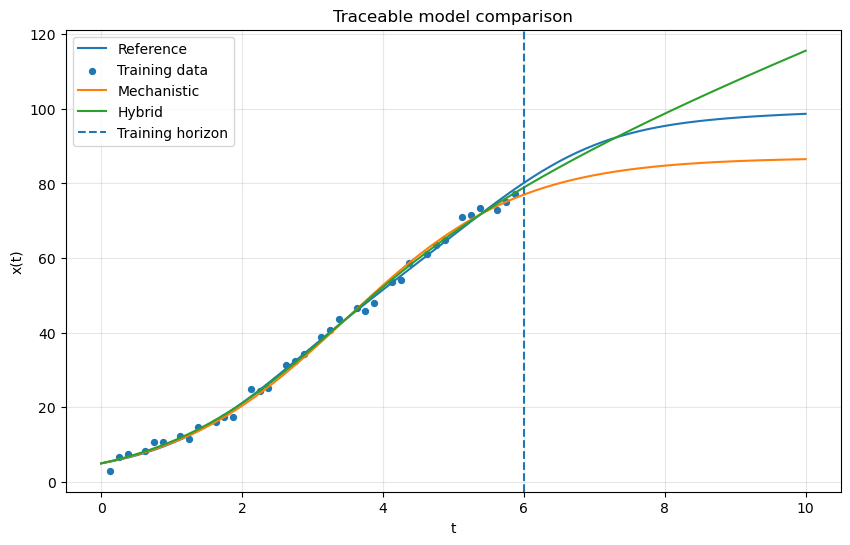

In [16]:
t_dense = np.linspace(
    CONFIG["time_start"],
    CONFIG["time_end"],
    400
)

plt.figure(figsize=(10, 6))

plt.plot(
    data["t"],
    data["y_reference"],
    label="Reference"
)

plt.scatter(
    train["t"],
    train["y_observed"],
    s=18,
    label="Training data"
)

plt.plot(
    t_dense,
    mechanistic_predict(t_dense),
    label="Mechanistic"
)

plt.plot(
    t_dense,
    hybrid_predict(t_dense),
    label="Hybrid"
)

plt.axvline(
    CONFIG["training_horizon"],
    linestyle="--",
    label="Training horizon"
)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Traceable model comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 20. Evidence table

Scientific claim не повинен посилатися на «графік вище».

Він повинен мати explicit evidence record.

In [17]:
EVIDENCE = pd.DataFrame([
    {
        "evidence_id": "EV01",
        "type": "calibration",
        "artifact": "THETA01",
        "value": (
            f"r={PARAMETERS['r_hat']:.4f}; "
            f"K={PARAMETERS['K_hat']:.4f}"
        ),
        "supports": "mechanistic baseline"
    },
    {
        "evidence_id": "EV02",
        "type": "interpolation",
        "artifact": "R01",
        "value": (
            f"RMSE_M="
            f"{get_rmse('Mechanistic','Interpolation'):.4f}; "
            f"RMSE_H="
            f"{get_rmse('Hybrid','Interpolation'):.4f}"
        ),
        "supports": "within-domain comparison"
    },
    {
        "evidence_id": "EV03",
        "type": "extrapolation",
        "artifact": "R01",
        "value": (
            f"RMSE_M={rmse_mech_extra:.4f}; "
            f"RMSE_H={rmse_hybrid_extra:.4f}; "
            f"Delta={DELTA_RMSE:.4f}"
        ),
        "supports": "C01"
    }
])

EVIDENCE

,evidence_id,type,artifact,value,supports
0,EV01,calibration,THETA01,r=0.8073; K=86.9607,mechanistic baseline
1,EV02,interpolation,R01,RMSE_M=1.8600; RMSE_H=1.4432,within-domain comparison
2,EV03,extrapolation,R01,RMSE_M=10.0183; RMSE_H=8.2485; Delta=1.7699,C01


# 21. Bounded claim

Автоматично сформуємо *computational statement*.

Це не claim about real system.

In [18]:
if DELTA_RMSE > 0:
    direction = (
        "hybrid model мала менший "
        "extrapolation RMSE"
    )
else:
    direction = (
        "hybrid model не мала меншого "
        "extrapolation RMSE"
    )

CLAIM_C01 = (
    "У межах synthetic system D01, "
    "experiment E01, training horizon "
    f"t <= {CONFIG['training_horizon']:.1f} "
    "та extrapolation regime до "
    f"t = {CONFIG['time_end']:.1f}, "
    f"{direction} відносно calibrated "
    "mechanistic baseline. "
    "Цей результат не встановлює "
    "універсальної переваги hybrid models "
    "і не є твердженням про реальну систему."
)

print(
    CLAIM_C01
)

У межах synthetic system D01, experiment E01, training horizon t <= 6.0 та extrapolation regime до t = 10.0, hybrid model мала менший extrapolation RMSE відносно calibrated mechanistic baseline. Цей результат не встановлює універсальної переваги hybrid models і не є твердженням про реальну систему.


# 22. Claim--Evidence Traceability Matrix

Тепер claim має explicit trace.

In [19]:
TRACEABILITY = pd.DataFrame([
    {
        "claim_id": "C01",
        "claim_level": (
            "computational / "
            "model-based"
        ),
        "QoI": "RMSE_extrapolation",
        "evidence": "EV03",
        "result": "R01",
        "experiment": "E01",
        "model": "M01",
        "data": "D01",
        "parameters": "THETA01",
        "configuration_hash": CONFIG_HASH,
        "data_hash": DATA_HASH,
        "parameter_hash": PARAMETER_HASH
    }
])

TRACEABILITY

,claim_id,claim_level,QoI,evidence,result,experiment,model,data,parameters,configuration_hash,data_hash,parameter_hash
0,C01,computational / model-based,RMSE_extrapolation,EV03,R01,E01,M01,D01,THETA01,4830fbf1d75b,67490478e0ef,e3d244664e03


# 23. Provenance record

Збираємо metadata в один object.

In [20]:
PROVENANCE = {
    "artifact_version": "1.0",
    "configuration_hash": CONFIG_HASH,
    "data_hash": DATA_HASH,
    "parameter_hash": PARAMETER_HASH,
    "environment": ENVIRONMENT,
    "seed_policy": {
        "observation_seed": CONFIG[
            "observation_seed"
        ],
        "generator": (
            "numpy.random.default_rng"
        )
    },
    "pipeline_order": [
        "configuration",
        "environment",
        "data_generation",
        "data_split",
        "calibration",
        "hybrid_training",
        "evaluation",
        "claim_generation"
    ],
    "claim_ids": [
        "C01"
    ]
}

PROVENANCE

{'artifact_version': '1.0',
 'configuration_hash': '4830fbf1d75b',
 'data_hash': '67490478e0ef',
 'parameter_hash': 'e3d244664e03',
 'environment': {'python': '3.11.14',
  'platform': 'Windows-10-10.0.19045-SP0',
  'numpy': '2.4.2',
  'pandas': '3.0.1',
  'scipy': '1.17.0',
  'scikit_learn': '1.8.0',
  'matplotlib': '3.10.8'},
 'seed_policy': {'observation_seed': 101,
  'generator': 'numpy.random.default_rng'},
 'pipeline_order': ['configuration',
  'environment',
  'data_generation',
  'data_split',
  'calibration',
  'hybrid_training',
  'evaluation',
  'claim_generation'],
 'claim_ids': ['C01']}

# 24. Reproducibility audit

Автоматичні checks не замінюють methodological audit, але можуть виявити частину помилок.

In [21]:
checks = []

def add_check(
    name,
    passed,
    evidence
):
    checks.append({
        "check": name,
        "passed": bool(passed),
        "evidence": evidence
    })

add_check(
    "Configuration fingerprint exists",
    len(CONFIG_HASH) == 12,
    CONFIG_HASH
)

add_check(
    "Data fingerprint exists",
    len(DATA_HASH) == 12,
    DATA_HASH
)

add_check(
    "Calibration converged",
    PARAMETERS["success"],
    PARAMETERS["loss"]
)

add_check(
    "Training and extrapolation separated",
    (
        train["t"].max()
        <= CONFIG["training_horizon"]
        and
        extrap_test["t"].min()
        > CONFIG["training_horizon"]
    ),
    (
        f"train_max={train['t'].max():.3f}; "
        f"extra_min={extrap_test['t'].min():.3f}"
    )
)

add_check(
    "Primary result finite",
    np.isfinite(
        DELTA_RMSE
    ),
    DELTA_RMSE
)

add_check(
    "Claim linked to evidence",
    (
        TRACEABILITY.loc[
            0,
            "evidence"
        ]
        in EVIDENCE[
            "evidence_id"
        ].values
    ),
    TRACEABILITY.loc[
        0,
        "evidence"
    ]
)

REPRO_AUDIT = pd.DataFrame(
    checks
)

REPRO_AUDIT

,check,passed,evidence
0,Configuration fingerprint exists,True,4830fbf1d75b
1,Data fingerprint exists,True,67490478e0ef
2,Calibration converged,True,76.288328
3,Training and extrapolation separated,True,train_max=5.875; extra_min=6.125
4,Primary result finite,True,1.769861
5,Claim linked to evidence,True,EV03


# 25. Claim audit

Тепер перевіряємо не code, а inference.

| Питання | Відповідь |
|---|---|
| Чи визначено claim level? | computational / model-based |
| Чи вказано domain? | synthetic D01, $0<t\le10$ |
| Чи вказано training horizon? | так |
| Чи визначено QoI? | $RMSE_{extra}$ |
| Чи є незалежний extrapolation regime? | так |
| Чи claim пов'язаний з evidence? | EV03 |
| Чи є provenance? | так |
| Чи claim переноситься на real system? | ні |
| Чи доводить result правильність mechanism? | ні |
| Чи доводить універсальну перевагу hybrid models? | ні |

# 26. Що ще не включено в цей compact example

Наш final artifact *не означає*, що враховано всі uncertainty sources.

У compact educational case не проведено повний:

- parameter UQ;
- model-form ensemble;
- sensitivity analysis;
- numerical verification;
- independent empirical validation.

У реальному artifact ці components повинні бути пов'язані з відповідними результатами ЛР5--ЛР7.

Це важливий принцип:

$$
\text{reproducible}
\not\Rightarrow
\text{valid}.
$$

І навпаки:

$$
\text{credible result without provenance}
$$

важко незалежно перевірити.

# 27. Reproducibility vs credibility

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Reproducibility") --> C("Research-grade<br/>evidence")
 B("Model<br/>credibility") --> C
 C --> D("Bounded<br/>scientific claim")
```

Потрібні обидві лінії:

$$
\text{Can we reproduce it?}
$$

і

$$
\text{Should we trust it for intended use?}
$$

# Частина II. Інтеграція артефактів ЛР1--ЛР7

# 28. Artifact inventory

Заповніть таблицю для власного курсового/дисертаційного кейсу.

| Version | Artifact | Основний зміст | Файл / ID | Status |
|---|---|---|---|---|
| v0.1 | Model Specification | formalization | | |
| v0.2 | Dynamic Model Specification | regimes / stochasticity | | |
| v0.3 | Network Model Specification | structure | | |
| v0.4 | Network Dynamics Specification | dynamics on network | | |
| v0.5 | Calibration Specification | identification / calibration | | |
| v0.6 | Model Credibility Report | V&V / SA / UQ | | |
| v0.7 | Hybrid Experiment Specification | design / hybrid comparison | | |
| v1.0 | Reproducible Research Artifact | integrated evidence | | |

Не всі dissertation systems є network systems.

Якщо певний artifact не застосовується, вкажіть:

> `N/A -- methodological reason: ...`

а не створюйте штучний network component.

# 29. Research Question Registry

Зафіксуйте RQ.

| Поле | Значення |
|---|---|
| RQ ID | |
| Research Question | |
| Scientific context | |
| Intended use | |
| System boundary | |
| Primary QoI | |
| Claim level | |
| Domain of validity | |

# 30. Model Registry

| Поле | Значення |
|---|---|
| Model ID | |
| Version | |
| Model class | |
| Mathematical formulation | |
| State variables | |
| Parameters | |
| Inputs | |
| Outputs | |
| Assumptions | |
| Limitations | |
| Code location | |

# 31. Data Registry

| Поле | Значення |
|---|---|
| Data ID | |
| Version | |
| Source | |
| Acquisition / generation | |
| Preprocessing | |
| Train/calibration role | |
| Validation role | |
| Test role | |
| Known limitations | |
| Fingerprint / checksum | |

# 32. Parameter Registry

| Parameter set | Model version | Estimation method | Data | Uncertainty | Status |
|---|---|---|---|---|---|
| | | | | | |

# 33. Credibility Registry

Інтегруйте evidence ЛР6.

| Evidence ID | Type | QoI / target | Result | Domain | Limitation |
|---|---|---|---|---|---|
| | verification | | | | |
| | validation | | | | |
| | sensitivity | | | | |
| | UQ | | | | |

# 34. Experiment Registry

Інтегруйте ЛР7.

| Experiment ID | RQ | Factors | Controls | QoI | Replications | Result |
|---|---|---|---|---|---|---|
| | | | | | | |

# 35. Claim Registry

Кожний scientific claim отримує ID.

| Claim ID | Claim | Level | Domain | Evidence | Limitation |
|---|---|---|---|---|---|
| C01 | | computational | | | |
| C02 | | model-based | | | |

Claim about real system додавайте лише за наявності відповідного empirical/theoretical justification.

# 36. Claim--Evidence Traceability Matrix

| Claim | QoI | Evidence | Experiment | Model | Data | Parameters | Figure/Table |
|---|---|---|---|---|---|---|---|
| C01 | | | | | | | |
| C02 | | | | | | | |

Для кожного claim має бути можливість пройти назад:

$$
C
\leftarrow
R
\leftarrow
E
\leftarrow
M,D,\Theta.
$$

# 37. Uncertainty Registry

| Source | Type | Representation | Propagated? | Evidence | Limitation |
|---|---|---|---|---|---|
| parameter | epistemic | | | | |
| observation | aleatoric / epistemic | | | | |
| initial state | | | | | |
| stochastic process | | | | | |
| numerical | | | | | |
| model form | | | | | |
| scenario | | | | | |

# 38. Reproducibility Manifest

| Component | Required | Present? | Identifier |
|---|---:|---:|---|
| Research Question | yes | | |
| Model specification | yes | | |
| Source code | yes | | |
| Data | yes | | |
| Parameters | yes | | |
| Configuration | yes | | |
| Environment | yes | | |
| Randomness policy | if applicable | | |
| V&V evidence | yes | | |
| SA/UQ evidence | if applicable | | |
| Experiment protocol | yes | | |
| Results | yes | | |
| Figures/tables | yes | | |
| Claims | yes | | |
| Provenance | yes | | |
| Limitations | yes | | |

# 39. README for artifact

Ваш research artifact повинен мати короткий README із такими блоками:

```text
# Project title

## Research Question

## Intended use

## Repository / artifact structure

## Environment

## Data

## Configuration

## How to reproduce

## Expected outputs

## Evidence and claims

## Limitations
```

# 40. Мінімальна структура каталогу

Один із можливих варіантів:

```text
research-artifact/
|
|-- README.md
|-- environment.yml
|-- config/
|   `-- experiment.yaml
|-- data/
|   |-- raw/
|   `-- processed/
|-- src/
|   |-- model.py
|   |-- calibration.py
|   `-- experiment.py
|-- notebooks/
|   `-- analysis.ipynb
|-- results/
|   |-- tables/
|   `-- figures/
|-- reports/
|   `-- research-report.qmd
`-- CITATION.cff
```

Це не жорсткий шаблон.

Структура повинна відповідати complexity project.

# 41. Final reproducibility test

Перед здачею:

1. Restart Kernel.
2. Run All.
3. Переконайтеся, що всі outputs regenerated.
4. Перевірте відсутність absolute local paths.
5. Перевірте versions environment.
6. Перевірте seeds/randomness policy.
7. Перевірте, що figures/tables генеруються code.
8. Перевірте, що claims посилаються на актуальні evidence IDs.
9. Перевірте, що old model versions не змішані з new results.
10. Перевірте limitations.

# 42. Claim stress test

Для кожного claim поставте питання:

1. Що саме стверджується?
2. На якому рівні -- computational, model-based чи real-system?
3. Який QoI підтримує claim?
4. Який experiment породив evidence?
5. Чи experiment знаходиться у validated domain?
6. Які uncertainty sources враховані?
7. Які не враховані?
8. Чи є competing explanation?
9. Чи зміниться claim при plausible alternative model?
10. Де проходить межа generalization?

# 43. Reproducible Research Artifact v1.0

Фінальний паспорт.

| Компонент | Специфікація |
|---|---|
| Artifact ID | |
| Version | 1.0 |
| Research Question | |
| Intended use | |
| System boundary | |
| Model ID / version | |
| Data ID / version | |
| Parameter set | |
| Configuration ID | |
| Environment | |
| Primary QoI | |
| Verification evidence | |
| Validation evidence | |
| Sensitivity evidence | |
| UQ evidence | |
| Experiment ID | |
| Hybrid/data-driven component | |
| Primary result | |
| Claim IDs | |
| Claim levels | |
| Domain of validity | |
| Unsupported claims | |
| Provenance record | |
| Reproduction procedure | |
| Known limitations | |
| Next experiment | |

# 44. Підсумкова схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Research<br/>Question") --> B("Versioned model<br/>+ data")
 B --> C("Credibility<br/>evidence")
 C --> D("Designed<br/>experiment")
 D --> E("Generated<br/>results")
 E --> F("Evidence<br/>registry")
 F --> G("Traceable<br/>claim")
 G --> H("Reproducible Research<br/>Artifact v1.0")
```

# Контрольні питання

1. Чому notebook сам по собі не є research artifact?
2. Що входить до Reproducible Research Artifact?
3. Що означає `Restart Kernel → Run All`?
4. Що таке hidden state?
5. Чому configuration потрібно зберігати окремо?
6. Що таке computational environment?
7. Для чого потрібен fingerprint/hash?
8. Чи доводить hash correctness data?
9. Що таке provenance?
10. Що таке artifact manifest?
11. Що таке Research Question Registry?
12. Для чого потрібен Model Registry?
13. Яку роль виконує Data Registry?
14. Навіщо versionувати parameter sets?
15. Що таке Credibility Registry?
16. Що таке Experiment Registry?
17. Що таке Claim Registry?
18. Що таке Claim--Evidence Traceability Matrix?
19. Як пройти від claim назад до model/data?
20. Чому result table має генеруватися автоматично?
21. Чому figure не повинна бути єдиним evidence?
22. Чим computational statement відрізняється від model-based inference?
23. Коли можливий claim about real system?
24. Чому reproducibility не означає validity?
25. Чому credibility без provenance недостатня для незалежної перевірки?
26. Що має містити uncertainty registry?
27. Що таке reproducibility manifest?
28. Що має містити README research artifact?
29. Чому absolute local paths небажані?
30. Що потрібно документувати для stochastic experiment?
31. Що перевіряє claim stress test?
32. Чому потрібно явно вказувати unsupported claims?
33. Чому old validation evidence не можна автоматично переносити на new model version?
34. Що означає bounded scientific claim?
35. Яка роль intended use?
36. Як domain of validity обмежує claim?
37. Що таке next discriminating experiment?
38. Як пов'язані artifacts v0.1--v0.7?
39. Чому v1.0 є інтеграцією, а не просто наступною версією model?
40. У якому сенсі завершений artifact є інструментом отримання нового наукового знання?

# Вимоги до звіту

У фінальному `.ipynb` / research artifact мають бути:

- Research Question;
- intended use;
- artifact manifest;
- model/data/parameter versions;
- explicit configuration;
- environment metadata;
- randomness policy;
- executable pipeline;
- V&V evidence;
- SA/UQ evidence або аргументоване `N/A`;
- experimental protocol;
- generated result table;
- evidence registry;
- Claim Registry;
- Claim--Evidence Traceability Matrix;
- uncertainty registry;
- reproducibility manifest;
- bounded claim;
- unsupported claims;
- limitations;
- `Reproducible Research Artifact v1.0`;
- reproduction instructions.

::: callout-important
## Критерій якості фінальної роботи

Сильний результат ЛР8 -- не «весь code запускається».

Сильний результат:

$$
\boxed{
\text{кожний claim має evidence,
а кожний evidence має provenance}
}
$$

У скороченій формі:

$$
\text{claim}
\leftrightarrow
\text{evidence}
\leftrightarrow
\text{experiment}
\leftrightarrow
\text{model/data/configuration}.
$$
:::

# Висновки

У висновках дайте відповіді:

1. Яке Research Question досліджувалося?
2. Який intended use model?
3. Які artifacts інтегровано?
4. Яка model version використана?
5. Яка data version використана?
6. Який parameter set використано?
7. Як зафіксовано configuration?
8. Як зафіксовано environment?
9. Як задокументовано randomness?
10. Які verification/validation evidence використано?
11. Які sensitivity/UQ evidence використано?
12. Який experiment підтримує primary claim?
13. Який primary QoI?
14. Який primary result?
15. Який bounded claim підтримується?
16. Які claims не підтримуються?
17. Які uncertainty sources не враховано?
18. Як забезпечено provenance?
19. Чи проходить artifact `Restart Kernel → Run All`?
20. Який наступний experiment найбільше посилить evidence?

# Джерела та корисні ресурси

Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [Jupyter](https://jupyter.org/)
- [Quarto](https://quarto.org/)
- [Git documentation](https://git-scm.com/doc)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [pandas documentation](https://pandas.pydata.org/docs/)
- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [scikit-learn documentation](https://scikit-learn.org/stable/)

# References